<a href="https://colab.research.google.com/github/HarshMittal03/data-analytics-projects/blob/main/capston_project6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CAPSTON PROJECT 6 COINTAB DATA ANALYST CHALLENGES

---




#HARSH MITTAL/DS08/SKILLCIRCLE

. Project Objective
Business Problem

Company X ships thousands of ecommerce orders through courier partners. Since courier charges are significant, Company X wants to verify whether each courier invoice has been billed correctly.



Import Libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Upload Files in Google Colab

In [ ]:
order_file = "Company X - Order Report.xlsx"
sku_file = "Company X - SKU Master.xlsx"
pincode_file = "Company X - Pincode Zones.xlsx"
invoice_file = "Courier Company - Invoice.xlsx"
rates_file = "Courier Company - Rates.xlsx"

orders = pd.read_excel(order_file)
sku_master = pd.read_excel(sku_file)
pincode_zones = pd.read_excel(pincode_file)
invoice = pd.read_excel(invoice_file)
rates_df = pd.read_excel(rates_file)


Display First Five Rows

In [ ]:
display(orders.head())
display(sku_master.head())
display(pincode_zones.head())
display(invoice.head())
display(rates_df.head())

,ExternOrderNo,SKU,Order Qty
0,2001827036,8904223818706,1.0
1,2001827036,8904223819093,1.0
2,2001827036,8904223819109,1.0
3,2001827036,8904223818430,1.0
4,2001827036,8904223819277,1.0


,SKU,Weight (g)
0,8904223815682,210
1,8904223815859,165
2,8904223815866,113
3,8904223815873,65
4,8904223816214,120


,Warehouse Pincode,Customer Pincode,Zone
0,121003,507101,d
1,121003,486886,d
2,121003,532484,d
3,121003,143001,b
4,121003,515591,d


,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone,Type of Shipment,Billing Amount (Rs.)
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4


,fwd_a_fixed,fwd_a_additional,fwd_b_fixed,fwd_b_additional,fwd_c_fixed,fwd_c_additional,fwd_d_fixed,fwd_d_additional,fwd_e_fixed,fwd_e_additional,rto_a_fixed,rto_a_additional,rto_b_fixed,rto_b_additional,rto_c_fixed,rto_c_additional,rto_d_fixed,rto_d_additional,rto_e_fixed,rto_e_additional
0,29.5,23.6,33,28.3,40.1,38.9,45.4,44.8,56.6,55.5,13.6,23.6,20.5,28.3,31.9,38.9,41.3,44.8,50.7,55.5


In [ ]:
display(orders.tail())
display(sku_master.tail())
display(pincode_zones.tail())
display(invoice.tail())
display(rates_df.tail())

,ExternOrderNo,SKU,Order Qty
395,2001806229,8904223818942,1.0
396,2001806229,8904223818850,1.0
397,2001806226,8904223818850,2.0
398,2001806210,8904223816214,1.0
399,2001806210,8904223818874,1.0


,SKU,Weight (g)
61,8904223819505,210
62,8904223819499,210
63,8904223819512,210
64,8904223819543,300
65,SACHETS001,10


,Warehouse Pincode,Customer Pincode,Zone
119,121003,325207,b
120,121003,303702,b
121,121003,313301,b
122,121003,173212,e
123,121003,302020,b


,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone,Type of Shipment,Billing Amount (Rs.)
119,1091118551656,2001812941,0.73,121003,325207,d,Forward charges,90.2
120,1091117614452,2001809383,0.50,121003,303702,d,Forward and RTO charges,86.7
121,1091120922803,2001820978,0.50,121003,313301,d,Forward charges,45.4
122,1091121844806,2001811475,0.50,121003,173212,b,Forward charges,33.0
123,1091121846136,2001811305,0.50,121003,302020,d,Forward charges,45.4


,fwd_a_fixed,fwd_a_additional,fwd_b_fixed,fwd_b_additional,fwd_c_fixed,fwd_c_additional,fwd_d_fixed,fwd_d_additional,fwd_e_fixed,fwd_e_additional,rto_a_fixed,rto_a_additional,rto_b_fixed,rto_b_additional,rto_c_fixed,rto_c_additional,rto_d_fixed,rto_d_additional,rto_e_fixed,rto_e_additional
0,29.5,23.6,33,28.3,40.1,38.9,45.4,44.8,56.6,55.5,13.6,23.6,20.5,28.3,31.9,38.9,41.3,44.8,50.7,55.5


Understand Dataset Shapes

In [ ]:
print("Orders:", orders.shape)
print("SKU Master:", sku_master.shape)
print("Pincode Zones:", pincode_zones.shape)
print("Invoice:", invoice.shape)
print("Rates:", rates_df.shape)


Orders: (400, 3)
SKU Master: (66, 2)
Pincode Zones: (124, 3)
Invoice: (124, 8)
Rates: (1, 20)


Check Dataset Information

In [ ]:
print("Orders info")
orders.info()

print("\nSKU Master info")
sku_master.info()

print("\nPincode Zones info")
pincode_zones.info()

print("\nInvoice info")
invoice.info()

print("\rates_df info")
rates_df.info()

Orders info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ExternOrderNo  400 non-null    int64  
 1   SKU            400 non-null    object 
 2   Order Qty      400 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 9.5+ KB

SKU Master info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   SKU         66 non-null     object
 1   Weight (g)  66 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.2+ KB

Pincode Zones info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Warehouse Pincode  124 non-null    int64 
 1   Cus

Check Column Names

In [ ]:
print("Order Report Columns:")
print(orders.columns.tolist())

print("\nSKU Master Columns:")
print(sku_master.columns.tolist())

print("\nPincode Zones Columns:")
print(pincode_zones.columns.tolist())

print("\nCourier Invoice Columns:")
print(invoice.columns.tolist())

print("\nRates Columns:")
print(rates_df.columns.tolist())

Order Report Columns:
['ExternOrderNo', 'SKU', 'Order Qty']

SKU Master Columns:
['SKU', 'Weight (g)']

Pincode Zones Columns:
['Warehouse Pincode', 'Customer Pincode', 'Zone']

Courier Invoice Columns:
['AWB Code', 'Order ID', 'Charged Weight', 'Warehouse Pincode', 'Customer Pincode', 'Zone', 'Type of Shipment', 'Billing Amount (Rs.)']

Rates Columns:
['fwd_a_fixed', 'fwd_a_additional', 'fwd_b_fixed', 'fwd_b_additional', 'fwd_c_fixed', 'fwd_c_additional', 'fwd_d_fixed', 'fwd_d_additional', 'fwd_e_fixed', 'fwd_e_additional', 'rto_a_fixed', 'rto_a_additional', 'rto_b_fixed', 'rto_b_additional', 'rto_c_fixed', 'rto_c_additional', 'rto_d_fixed', 'rto_d_additional', 'rto_e_fixed', 'rto_e_additional']


Check Missing Values

In [ ]:
print("Orders info")
print(orders.isnull().sum())

print("\nSKU Master info")
print(sku_master.isnull().sum())

print("\nPincode Zones info")
print(pincode_zones.isnull().sum())

print("\nInvoice info")
print(invoice.isnull().sum())

print("\nRates info")
print(rates_df.isnull().sum())

Orders info
ExternOrderNo    0
SKU              0
Order Qty        0
dtype: int64

SKU Master info
SKU           0
Weight (g)    0
dtype: int64

Pincode Zones info
Warehouse Pincode    0
Customer Pincode     0
Zone                 0
dtype: int64

Invoice info
AWB Code                0
Order ID                0
Charged Weight          0
Warehouse Pincode       0
Customer Pincode        0
Zone                    0
Type of Shipment        0
Billing Amount (Rs.)    0
dtype: int64

Rates info
fwd_a_fixed         0
fwd_a_additional    0
fwd_b_fixed         0
fwd_b_additional    0
fwd_c_fixed         0
fwd_c_additional    0
fwd_d_fixed         0
fwd_d_additional    0
fwd_e_fixed         0
fwd_e_additional    0
rto_a_fixed         0
rto_a_additional    0
rto_b_fixed         0
rto_b_additional    0
rto_c_fixed         0
rto_c_additional    0
rto_d_fixed         0
rto_d_additional    0
rto_e_fixed         0
rto_e_additional    0
dtype: int64


Check Duplicate Records

In [ ]:
print("Orders info")
print(orders.duplicated().sum())

print("\nSKU Master info")
print(sku_master.duplicated().sum())

print("\nPincode Zones info")
print(pincode_zones.duplicated().sum())

print("\nInvoice info")
print(invoice.duplicated().sum())

print("\nRates info")
print(rates_df.duplicated().sum())

Orders info
2

SKU Master info
1

Pincode Zones info
16

Invoice info
0

Rates info
0


In [ ]:
print("Orders info - Rows after dropping duplicates:")
print(orders.drop_duplicates().shape[0])

print("\nSKU Master info - Rows after dropping duplicates:")
print(sku_master.drop_duplicates().shape[0])

print("\nPincode Zones info - Rows after dropping duplicates:")
print(pincode_zones.drop_duplicates().shape[0])

print("\nInvoice info - Rows after dropping duplicates:")
print(invoice.drop_duplicates().shape[0])

print("\nRates info - Rows after dropping duplicates:")
print(rates_df.drop_duplicates().shape[0])

Orders info - Rows after dropping duplicates:
398

SKU Master info - Rows after dropping duplicates:
65

Pincode Zones info - Rows after dropping duplicates:
108

Invoice info - Rows after dropping duplicates:
124

Rates info - Rows after dropping duplicates:
1


In [ ]:
orders.drop_duplicates(inplace=True)
sku_master.drop_duplicates(inplace=True)
pincode_zones.drop_duplicates(inplace=True)
invoice.drop_duplicates(inplace=True)
rates_df.drop_duplicates(inplace=True)

Now that duplicates have been permanently removed, let's verify the shapes and check for duplicates again.

In [ ]:
print('Shapes after dropping duplicates:')
print('Orders:', orders.shape)
print('SKU Master:', sku_master.shape)
print('Pincode Zones:', pincode_zones.shape)
print('Invoice:', invoice.shape)
print('Rates:', rates_df.shape)

print('\nDuplicate counts after dropping duplicates:')
print('Orders:', orders.duplicated().sum())
print('SKU Master:', sku_master.duplicated().sum())
print('Pincode Zones:', pincode_zones.duplicated().sum())
print('Invoice:', invoice.duplicated().sum())
print('Rates:', rates_df.duplicated().sum())

Shapes after dropping duplicates:
Orders: (398, 3)
SKU Master: (65, 2)
Pincode Zones: (108, 3)
Invoice: (124, 8)
Rates: (1, 20)

Duplicate counts after dropping duplicates:
Orders: 0
SKU Master: 0
Pincode Zones: 0
Invoice: 0
Rates: 0


In [ ]:
print("Orders info")
print(orders.duplicated().sum())

print("\nSKU Master info")
print(sku_master.duplicated().sum())

print("\nPincode Zones info")
print(pincode_zones.duplicated().sum())

print("\nInvoice info")
print(invoice.duplicated().sum())

print("\nRates info")
print(rates_df.duplicated().sum())

Orders info
0

SKU Master info
0

Pincode Zones info
0

Invoice info
0

Rates info
0


Check Unique Orders

Check Unique Orders

In [ ]:
print("Total rows in Order Report:",
      len(orders))

print("Unique Orders:",
      orders["ExternOrderNo"].nunique())

print("Unique SKUs:",
      orders["SKU"].nunique())

Total rows in Order Report: 398
Unique Orders: 124
Unique SKUs: 65


Check Shipment Types

In [ ]:
invoice["Type of Shipment"].value_counts()

,count
Type of Shipment,
Forward charges,109
Forward and RTO charges,15


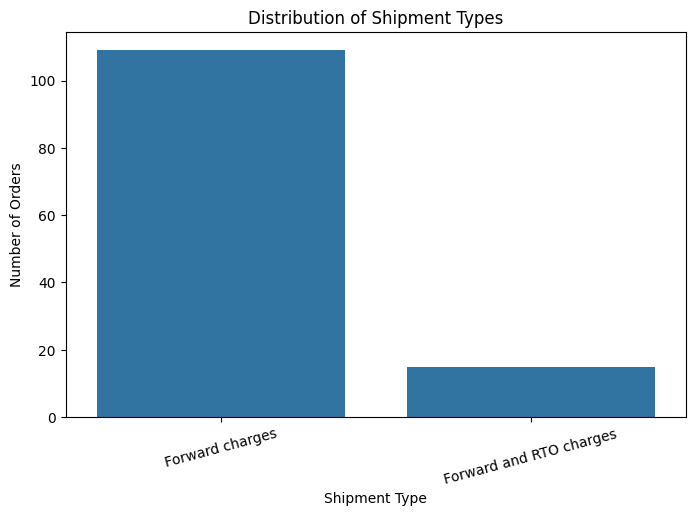

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=invoice,
    x="Type of Shipment"
)

plt.title("Distribution of Shipment Types")
plt.xlabel("Shipment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=15)

plt.show()

Check Courier Zones

In [ ]:
invoice["Zone"].value_counts()

,count
Zone,
d,98
b,24
e,2


Visualization:

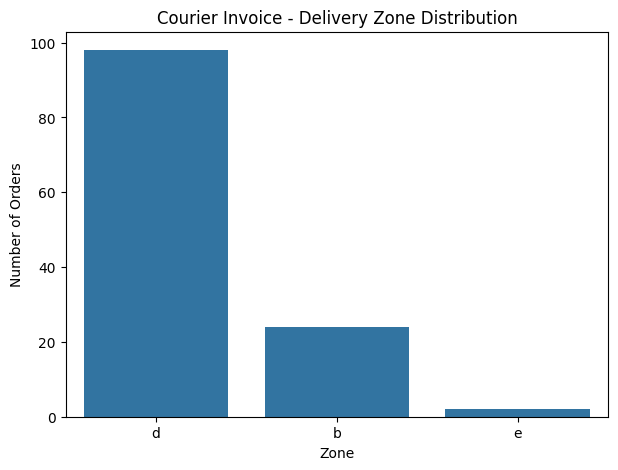

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=invoice,
    x="Zone"
)

plt.title("Courier Invoice - Delivery Zone Distribution")
plt.xlabel("Zone")
plt.ylabel("Number of Orders")

plt.show()

Merge Order Report with SKU Master

In [ ]:
order_data = pd.merge(
    orders,
    sku_master,
    on="SKU",
    how="left"
)

display(order_data.head())

,ExternOrderNo,SKU,Order Qty,Weight (g)
0,2001827036,8904223818706,1.0,127
1,2001827036,8904223819093,1.0,150
2,2001827036,8904223819109,1.0,100
3,2001827036,8904223818430,1.0,165
4,2001827036,8904223819277,1.0,350


Calculate weight of each SKU

In [ ]:
order_data["Weight KG"] = (
    order_data["Weight (g)"] / 1000
)

Calculate total weight considering quantity

In [ ]:
order_data["Total SKU Weight KG"] = (
    order_data["Weight KG"] *
    order_data["Order Qty"]
)

display(
    order_data[
        [
            "ExternOrderNo",
            "SKU",
            "Order Qty",
            "Weight (g)",
            "Total SKU Weight KG"
        ]
    ].head(10)
)

,ExternOrderNo,SKU,Order Qty,Weight (g),Total SKU Weight KG
0,2001827036,8904223818706,1.0,127,0.127
1,2001827036,8904223819093,1.0,150,0.150
2,2001827036,8904223819109,1.0,100,0.100
3,2001827036,8904223818430,1.0,165,0.165
4,2001827036,8904223819277,1.0,350,0.350
5,2001827036,GIFTBOX202002,1.0,500,0.500
6,2001827036,8904223818638,2.0,137,0.274
7,2001827036,SACHETS001,1.0,10,0.010
8,2001825261,8904223819024,4.0,112,0.448
9,2001825261,8904223819291,4.0,112,0.448


Calculate total weight of each order

In [ ]:
order_data["Total SKU Weight KG"] = (
    order_data["Weight KG"] * order_data["Order Qty"]
)

display(
    order_data[
        [
            "ExternOrderNo",
            "SKU",
            "Order Qty",
            "Weight KG",
            "Total SKU Weight KG"
        ]
    ].head()
)

,ExternOrderNo,SKU,Order Qty,Weight KG,Total SKU Weight KG
0,2001827036,8904223818706,1.0,0.127,0.127
1,2001827036,8904223819093,1.0,0.150,0.150
2,2001827036,8904223819109,1.0,0.100,0.100
3,2001827036,8904223818430,1.0,0.165,0.165
4,2001827036,8904223819277,1.0,0.350,0.350


Group Weight by Order ID

In [ ]:
order_weight = (
    order_data
    .groupby("ExternOrderNo", as_index=False)["Total SKU Weight KG"]
    .sum()
)

order_weight.rename(
    columns={
        "Total SKU Weight KG": "Total weight as per X (KG)"
    },
    inplace=True
)

display(order_weight.head())

,ExternOrderNo,Total weight as per X (KG)
0,2001806210,0.220
1,2001806226,0.480
2,2001806229,0.500
3,2001806232,1.302
4,2001806233,0.245


Check Total Weight

In [ ]:
print(
    "Total weight of all orders:",
    round(order_weight["Total weight as per X (KG)"].sum(), 3),
    "KG"
)

Total weight of all orders: 87.391 KG


Create Weight Slab Function

In [ ]:
def calculate_slab(weight):
    if weight <= 0:
        return 0
    return np.ceil(weight * 2 - 1e-10) / 2

Calculate Weight Slab as per X

In [ ]:
order_weight["Weight slab as per X (KG)"] = (
    order_weight["Total weight as per X (KG)"]
    .apply(calculate_slab)
)

display(order_weight.head(10))

,ExternOrderNo,Total weight as per X (KG),Weight slab as per X (KG)
0,2001806210,0.220,0.5
1,2001806226,0.480,0.5
2,2001806229,0.500,0.5
3,2001806232,1.302,1.5
4,2001806233,0.245,0.5
5,2001806251,0.245,0.5
6,2001806273,0.615,1.0
7,2001806304,0.500,0.5
8,2001806338,0.500,0.5
9,2001806408,2.265,2.5


Check Weight Slab Examples

In [ ]:
test_weights = [0.4, 0.95, 1, 2.2]

for weight in test_weights:
    print(
        "Weight:",
        weight,
        "KG -> Slab:",
        calculate_slab(weight),
        "KG"
    )

Weight: 0.4 KG -> Slab: 0.5 KG
Weight: 0.95 KG -> Slab: 1.0 KG
Weight: 1 KG -> Slab: 1.0 KG
Weight: 2.2 KG -> Slab: 2.5 KG


Check Pincode Zone Data

In [ ]:
display(pincode_zones.head())

print("Pincode zone rows:", len(pincode_zones))

,Warehouse Pincode,Customer Pincode,Zone
0,121003,507101,d
1,121003,486886,d
2,121003,532484,d
3,121003,143001,b
4,121003,515591,d


Pincode zone rows: 108


Remove Duplicate Pincode Mappings

In [ ]:
pincode_zones_clean = (
    pincode_zones[
        [
            "Warehouse Pincode",
            "Customer Pincode",
            "Zone"
        ]
    ]
    .drop_duplicates(
        subset=[
            "Warehouse Pincode",
            "Customer Pincode"
        ]
    )
)

print(
    "Pincode rows after removing duplicate mappings:",
    len(pincode_zones_clean)
)

Pincode rows after removing duplicate mappings: 108


Check Courier Invoice

In [ ]:
display(invoice.head())

print("invoice rows:", len(invoice))

print(
    "Unique invoice orders:",
    invoice["Order ID"].nunique()
)

,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone,Type of Shipment,Billing Amount (Rs.)
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4


invoice rows: 124
Unique invoice orders: 124


Merge X Weight Data with Courier Invoice

In [ ]:
result = pd.merge(
    invoice,
    order_weight,
    left_on="Order ID",
    right_on="ExternOrderNo",
    how="left"
)

display(result.head())

,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone,Type of Shipment,Billing Amount (Rs.),ExternOrderNo,Total weight as per X (KG),Weight slab as per X (KG)
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0,2001806232,1.302,1.5
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2,2001806273,0.615,1.0
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6,2001806408,2.265,2.5
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3,2001806458,0.700,1.0
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4,2001807012,0.240,0.5


Remove Unnecessary Column

In [ ]:
result.drop(
    columns=["ExternOrderNo"],
    inplace=True
)

display(result.head())

,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone,Type of Shipment,Billing Amount (Rs.),Total weight as per X (KG),Weight slab as per X (KG)
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0,1.302,1.5
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2,0.615,1.0
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6,2.265,2.5
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3,0.700,1.0
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4,0.240,0.5


Calculate Courier Weight Slab

In [ ]:
result["Weight slab charged by Courier Company (KG)"] = (
    result["Charged Weight"]
    .apply(calculate_slab)
)

display(
    result[
        [
            "Order ID",
            "Charged Weight",
            "Weight slab charged by Courier Company (KG)"
        ]
    ].head()
)

,Order ID,Charged Weight,Weight slab charged by Courier Company (KG)
0,2001806232,1.30,1.5
1,2001806273,1.00,1.0
2,2001806408,2.50,2.5
3,2001806458,1.00,1.0
4,2001807012,0.15,0.5


calculate Delivery Zone as per X

In [ ]:
result = pd.merge(
    result,
    pincode_zones_clean,
    on=[
        "Warehouse Pincode",
        "Customer Pincode"
    ],
    how="left"
)

# Rename the 'Zone_y' column (from pincode_zones_clean) to 'Delivery Zone as per X'
# The original 'Zone' column (from invoice) will become 'Zone_x'
result.rename(
    columns={
        "Zone_y": "Delivery Zone as per X",
        "Zone_x": "Zone as per Courier"
    },
    inplace=True
)

display(result.head())

,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone as per Courier,Type of Shipment,Billing Amount (Rs.),Total weight as per X (KG),Weight slab as per X (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0,1.302,1.5,1.5,d
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2,0.615,1.0,1.0,d
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6,2.265,2.5,2.5,d
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3,0.700,1.0,1.0,b
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4,0.240,0.5,0.5,d


Read the Rate Card

In [ ]:
rate = rates_df.iloc[0]

print("Rate card loaded successfully!")

display(rates_df)

Rate card loaded successfully!


,fwd_a_fixed,fwd_a_additional,fwd_b_fixed,fwd_b_additional,fwd_c_fixed,fwd_c_additional,fwd_d_fixed,fwd_d_additional,fwd_e_fixed,fwd_e_additional,rto_a_fixed,rto_a_additional,rto_b_fixed,rto_b_additional,rto_c_fixed,rto_c_additional,rto_d_fixed,rto_d_additional,rto_e_fixed,rto_e_additional
0,29.5,23.6,33,28.3,40.1,38.9,45.4,44.8,56.6,55.5,13.6,23.6,20.5,28.3,31.9,38.9,41.3,44.8,50.7,55.5


Create Expected Charge Function

The rate card contains:

fwd_a_fixed

fwd_a_additional

fwd_b_fixed

fwd_b_additional

...

rto_a_fixed

rto_a_additional

In [ ]:
def calculate_expected_charge(weight_slab, zone, shipment_type):

    zone = str(zone).lower()

    # Number of additional 0.5 KG slabs
    additional_units = max(
        0,
        int(round(weight_slab / 0.5)) - 1
    )

    # Forward charges
    fwd_fixed = rate[f"fwd_{zone}_fixed"]
    fwd_additional = rate[f"fwd_{zone}_additional"]

    forward_charge = (
        fwd_fixed +
        additional_units * fwd_additional
    )

    # RTO charges
    if str(shipment_type).strip().lower() == "forward and rto charges":

        rto_fixed = rate[f"rto_{zone}_fixed"]
        rto_additional = rate[f"rto_{zone}_additional"]

        rto_charge = (
            rto_fixed +
            additional_units * rto_additional
        )

        total_charge = forward_charge + rto_charge

    else:

        total_charge = forward_charge

    return total_charge

Rename Courier Billing Amount

In [ ]:
result.rename(
    columns={
        "Billing Amount (Rs.)":
        "Charges Billed by Courier Company (Rs.)"
    },
    inplace=True
)

display(result.head())

,AWB Code,Order ID,Charged Weight,Warehouse Pincode,Customer Pincode,Zone as per Courier,Type of Shipment,Charges Billed by Courier Company (Rs.),Total weight as per X (KG),Weight slab as per X (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X
0,1091117222124,2001806232,1.30,121003,507101,d,Forward charges,135.0,1.302,1.5,1.5,d
1,1091117222194,2001806273,1.00,121003,486886,d,Forward charges,90.2,0.615,1.0,1.0,d
2,1091117222931,2001806408,2.50,121003,532484,d,Forward charges,224.6,2.265,2.5,2.5,d
3,1091117223244,2001806458,1.00,121003,143001,b,Forward charges,61.3,0.700,1.0,1.0,b
4,1091117229345,2001807012,0.15,121003,515591,d,Forward charges,45.4,0.240,0.5,0.5,d


Create Charge Status

In [ ]:
def charge_status(difference):

    if np.isclose(difference, 0, atol=0.01):
        return "Correctly Charged"

    elif difference < 0:
        return "Overcharged"

    else:
        return "Undercharged"

# Re-calculate 'Expected Charge as per X (Rs.)' and 'Difference Between Expected Charges and Billed Charges (Rs.)'
# as the previous cell for this was deleted.
result["Expected Charge as per X (Rs.)"] = (
    result.apply(
        lambda row: calculate_expected_charge(
            row["Weight slab as per X (KG)"],
            row["Delivery Zone as per X"],
            row["Type of Shipment"]
        ),
        axis=1
    )
)

result["Difference Between Expected Charges and Billed Charges (Rs.)"] = (
    result["Expected Charge as per X (Rs.)"]
    - result["Charges Billed by Courier Company (Rs.)"]
)


result["Charge Status"] = (
    result[
        "Difference Between Expected Charges and Billed Charges (Rs.)"
    ]
    .apply(charge_status)
)

display(
    result[
        [
            "Order ID",
            "Difference Between Expected Charges and Billed Charges (Rs.)",
            "Charge Status"
        ]
    ].head(10)
)

,Order ID,Difference Between Expected Charges and Billed Charges (Rs.),Charge Status
0,2001806232,0.000000e+00,Correctly Charged
1,2001806273,-1.421085e-14,Correctly Charged
2,2001806408,0.000000e+00,Correctly Charged
3,2001806458,0.000000e+00,Correctly Charged
4,2001807012,0.000000e+00,Correctly Charged
5,2001806686,0.000000e+00,Correctly Charged
6,2001806885,-2.830000e+01,Overcharged
7,2001807058,0.000000e+00,Correctly Charged
8,2001807186,0.000000e+00,Correctly Charged
9,2001807290,0.000000e+00,Correctly Charged


Calculate Summary

In [ ]:
total_orders = len(result)

correct_orders = (
    result["Charge Status"]
    .eq("Correctly Charged")
    .sum()
)

overcharged_orders = (
    result["Charge Status"]
    .eq("Overcharged")
    .sum()
)

undercharged_orders = (
    result["Charge Status"]
    .eq("Undercharged")
    .sum()
)

total_overcharging = (
    -result.loc[
        result["Charge Status"] == "Overcharged",
        "Difference Between Expected Charges and Billed Charges (Rs.)"
    ].sum()
)

total_undercharging = (
    result.loc[
        result["Charge Status"] == "Undercharged",
        "Difference Between Expected Charges and Billed Charges (Rs.)"
    ].sum()
)

print("Total Orders:", total_orders)
print("Correctly Charged Orders:", correct_orders)
print("Overcharged Orders:", overcharged_orders)
print("Total Overcharging Amount: ₹", round(total_overcharging, 2))
print("Undercharged Orders:", undercharged_orders)
print("Total Undercharging Amount: ₹", round(total_undercharging, 2))

Total Orders: 124
Correctly Charged Orders: 21
Overcharged Orders: 80
Total Overcharging Amount: ₹ 4483.2
Undercharged Orders: 23
Total Undercharging Amount: ₹ 575.1


Create Summary Table

In [ ]:
summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Orders where X has been correctly charged",
        "Total Orders where X has been overcharged",
        "Total Overcharging Amount (Rs.)",
        "Total Orders where X has been undercharged",
        "Total Undercharging Amount (Rs.)"
    ],

    "Value": [
        total_orders,
        correct_orders,
        overcharged_orders,
        total_overcharging,
        undercharged_orders,
        total_undercharging
    ]
})

display(summary)

,Metric,Value
0,Total Orders,124.0
1,Total Orders where X has been correctly charged,21.0
2,Total Orders where X has been overcharged,80.0
3,Total Overcharging Amount (Rs.),4483.2
4,Total Orders where X has been undercharged,23.0
5,Total Undercharging Amount (Rs.),575.1


Calculate Total Expected and Billed Charges

In [ ]:
total_expected = result[
    "Expected Charge as per X (Rs.)"
].sum()

total_billed = result[
    "Charges Billed by Courier Company (Rs.)"
].sum()

print("Total Expected Charges: ₹", round(total_expected, 2))
print("Total Billed Charges: ₹", round(total_billed, 2))

print(
    "Net Difference: ₹",
    round(total_billed - total_expected, 2)
)

Total Expected Charges: ₹ 9740.1
Total Billed Charges: ₹ 13648.2
Net Difference: ₹ 3908.1


Create Final Order-Level Table

In [ ]:
final_columns = [
    "Order ID",
    "AWB Code",
    "Total weight as per X (KG)",
    "Weight slab as per X (KG)",
    "Charged Weight",
    "Weight slab charged by Courier Company (KG)",
    "Delivery Zone as per X",
    "Zone as per Courier",
    "Expected Charge as per X (Rs.)",
    "Charges Billed by Courier Company (Rs.)",
    "Difference Between Expected Charges and Billed Charges (Rs.)"
]

order_level = result[final_columns].copy()

Rename Final Columns Exactly

In [ ]:
order_level.rename(
    columns={
        "AWB Code": "AWB Number",
        "Charged Weight": "Total weight as per Courier Company (KG)",
        "Zone as per Courier": "Delivery Zone charged by Courier Company"
    },
    inplace=True
)

display(order_level.head(10))

,Order ID,AWB Number,Total weight as per X (KG),Weight slab as per X (KG),Total weight as per Courier Company (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X,Delivery Zone charged by Courier Company,Expected Charge as per X (Rs.),Charges Billed by Courier Company (Rs.),Difference Between Expected Charges and Billed Charges (Rs.)
0,2001806232,1091117222124,1.302,1.5,1.30,1.5,d,d,135.0,135.0,0.000000e+00
1,2001806273,1091117222194,0.615,1.0,1.00,1.0,d,d,90.2,90.2,-1.421085e-14
2,2001806408,1091117222931,2.265,2.5,2.50,2.5,d,d,224.6,224.6,0.000000e+00
3,2001806458,1091117223244,0.700,1.0,1.00,1.0,b,b,61.3,61.3,0.000000e+00
4,2001807012,1091117229345,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.000000e+00
5,2001806686,1091117229555,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.000000e+00
6,2001806885,1091117229776,0.420,0.5,1.00,1.0,b,b,33.0,61.3,-2.830000e+01
7,2001807058,1091117323112,1.168,1.5,1.15,1.5,b,b,89.6,89.6,0.000000e+00
8,2001807186,1091117323812,0.500,0.5,0.50,0.5,d,d,45.4,45.4,0.000000e+00
9,2001807290,1091117324206,0.500,0.5,0.50,0.5,d,d,45.4,45.4,0.000000e+00


Round Numerical Values

In [ ]:
order_level[
    "Total weight as per X (KG)"
] = order_level[
    "Total weight as per X (KG)"
].round(3)

order_level[
    "Weight slab as per X (KG)"
] = order_level[
    "Weight slab as per X (KG)"
].round(2)

order_level[
    "Total weight as per Courier Company (KG)"
] = order_level[
    "Total weight as per Courier Company (KG)"
].round(3)

order_level[
    "Weight slab charged by Courier Company (KG)"
] = order_level[
    "Weight slab charged by Courier Company (KG)"
].round(2)

order_level[
    "Expected Charge as per X (Rs.)"
] = order_level[
    "Expected Charge as per X (Rs.)"
].round(2)

order_level[
    "Charges Billed by Courier Company (Rs.)"
] = order_level[
    "Charges Billed by Courier Company (Rs.)"
].round(2)

order_level[
    "Difference Between Expected Charges and Billed Charges (Rs.)"
] = order_level[
    "Difference Between Expected Charges and Billed Charges (Rs.)"
].round(2)

display(order_level.head(10))

,Order ID,AWB Number,Total weight as per X (KG),Weight slab as per X (KG),Total weight as per Courier Company (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X,Delivery Zone charged by Courier Company,Expected Charge as per X (Rs.),Charges Billed by Courier Company (Rs.),Difference Between Expected Charges and Billed Charges (Rs.)
0,2001806232,1091117222124,1.302,1.5,1.30,1.5,d,d,135.0,135.0,0.0
1,2001806273,1091117222194,0.615,1.0,1.00,1.0,d,d,90.2,90.2,-0.0
2,2001806408,1091117222931,2.265,2.5,2.50,2.5,d,d,224.6,224.6,0.0
3,2001806458,1091117223244,0.700,1.0,1.00,1.0,b,b,61.3,61.3,0.0
4,2001807012,1091117229345,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.0
5,2001806686,1091117229555,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.0
6,2001806885,1091117229776,0.420,0.5,1.00,1.0,b,b,33.0,61.3,-28.3
7,2001807058,1091117323112,1.168,1.5,1.15,1.5,b,b,89.6,89.6,0.0
8,2001807186,1091117323812,0.500,0.5,0.50,0.5,d,d,45.4,45.4,0.0
9,2001807290,1091117324206,0.500,0.5,0.50,0.5,d,d,45.4,45.4,0.0


Final Data Validation

In [ ]:
print("Final order-level rows:", len(order_level))

print(
    "Unique Order IDs:",
    order_level["Order ID"].nunique()
)

print(
    "Duplicate Order IDs:",
    order_level["Order ID"].duplicated().sum()
)

print(
    "Missing values:",
    order_level.isnull().sum().sum()
)

Final order-level rows: 124
Unique Order IDs: 124
Duplicate Order IDs: 0
Missing values: 0


Add Status for Internal Working

In [ ]:
order_level_working = order_level.copy()

order_level_working["Charge Status"] = result[
    "Charge Status"
].values

display(order_level_working.head())

,Order ID,AWB Number,Total weight as per X (KG),Weight slab as per X (KG),Total weight as per Courier Company (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X,Delivery Zone charged by Courier Company,Expected Charge as per X (Rs.),Charges Billed by Courier Company (Rs.),Difference Between Expected Charges and Billed Charges (Rs.),Charge Status
0,2001806232,1091117222124,1.302,1.5,1.30,1.5,d,d,135.0,135.0,0.0,Correctly Charged
1,2001806273,1091117222194,0.615,1.0,1.00,1.0,d,d,90.2,90.2,-0.0,Correctly Charged
2,2001806408,1091117222931,2.265,2.5,2.50,2.5,d,d,224.6,224.6,0.0,Correctly Charged
3,2001806458,1091117223244,0.700,1.0,1.00,1.0,b,b,61.3,61.3,0.0,Correctly Charged
4,2001807012,1091117229345,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.0,Correctly Charged


Visualization 1: Charge Status

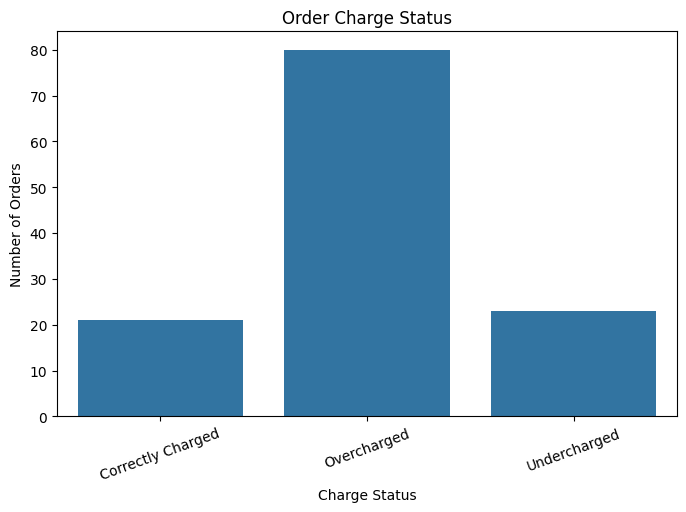

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=order_level_working,
    x="Charge Status"
)

plt.title("Order Charge Status")
plt.xlabel("Charge Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)

plt.show()

Visualization 2: Expected vs Billed Charges

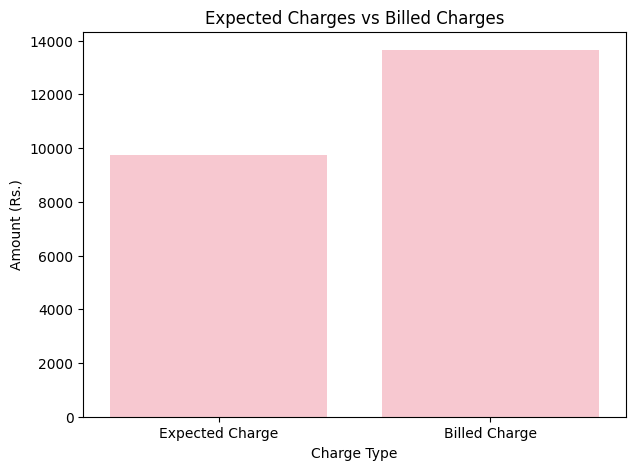

In [ ]:
comparison = pd.DataFrame({
    "Charge Type": [
        "Expected Charge",
        "Billed Charge"
    ],
    "Amount": [
        total_expected,
        total_billed
    ]
})

plt.figure(figsize=(7,5))

sns.barplot(
    data=comparison,
    x="Charge Type",
    y="Amount",color="pink"
)

plt.title("Expected Charges vs Billed Charges")
plt.ylabel("Amount (Rs.)")

plt.show()

Visualization 3: Weight Slab Distribution

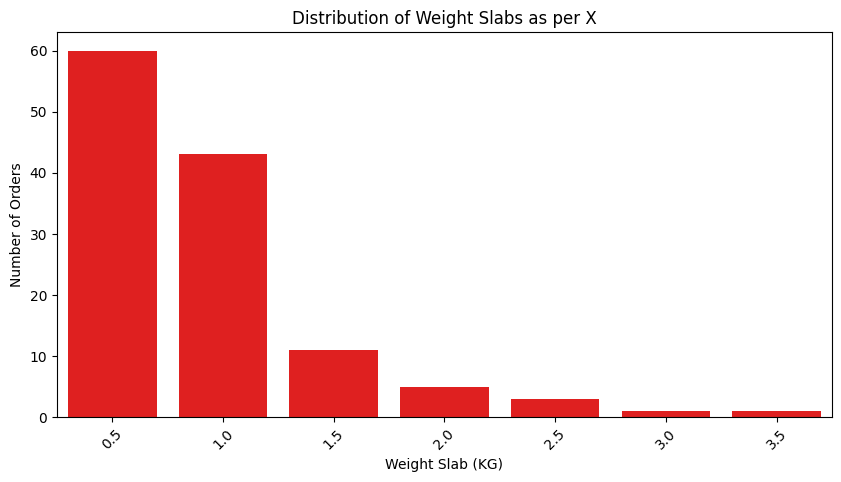

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=order_level_working,
    x="Weight slab as per X (KG)",color="red"
)

plt.title("Distribution of Weight Slabs as per X")
plt.xlabel("Weight Slab (KG)")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

Visualization 4: X Zone Distribution

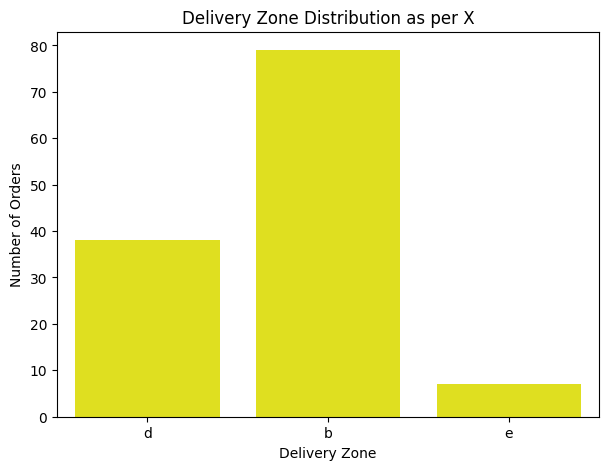

In [ ]:

plt.figure(figsize=(7,5))

sns.countplot(
    data=order_level_working,
    x="Delivery Zone as per X",color="yellow"
)

plt.title("Delivery Zone Distribution as per X")
plt.xlabel("Delivery Zone")
plt.ylabel("Number of Orders")

plt.show()

Visualization 5: Courier Zone Distribution

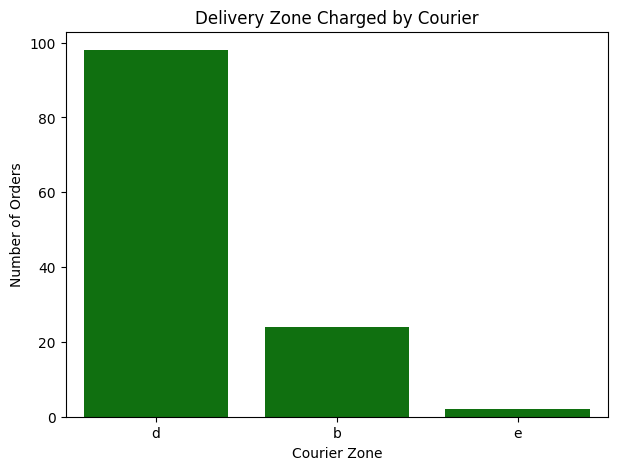

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=order_level_working,
    x="Delivery Zone charged by Courier Company",color="green"
)

plt.title("Delivery Zone Charged by Courier")
plt.xlabel("Courier Zone")
plt.ylabel("Number of Orders")

plt.show()

Visualization 6: Difference Distribution

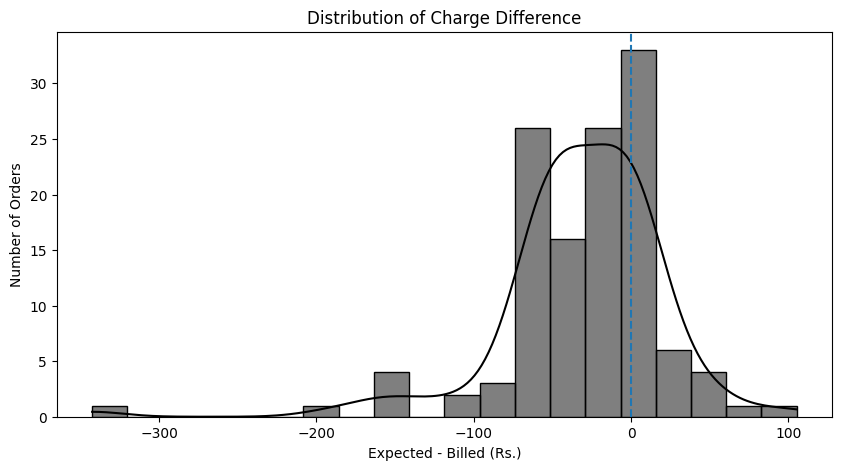

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=order_level_working,
    x="Difference Between Expected Charges and Billed Charges (Rs.)",
    bins=20,
    kde=True,color="black"
)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Charge Difference")
plt.xlabel("Expected - Billed (Rs.)")
plt.ylabel("Number of Orders")

plt.show()

Visualization 7: Expected Charges by Zone

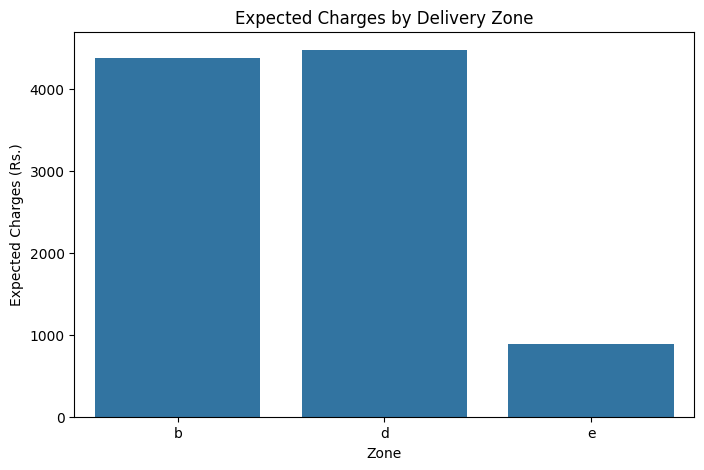

In [ ]:
zone_charges = (
    order_level_working
    .groupby("Delivery Zone as per X")[
        "Expected Charge as per X (Rs.)"
    ]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=zone_charges,
    x="Delivery Zone as per X",
    y="Expected Charge as per X (Rs.)"
)

plt.title("Expected Charges by Delivery Zone")
plt.xlabel("Zone")
plt.ylabel("Expected Charges (Rs.)")

plt.show()

Visualization 8: Billed Charges by Zone

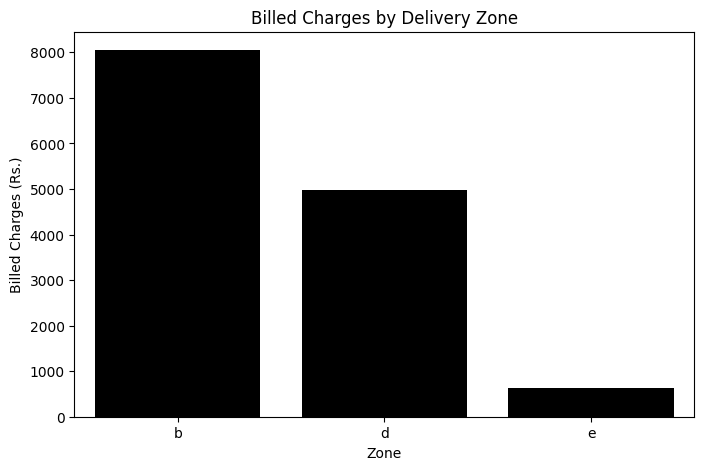

In [ ]:
zone_billed = (
    order_level_working
    .groupby("Delivery Zone as per X")[
        "Charges Billed by Courier Company (Rs.)"
    ]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=zone_billed,
    x="Delivery Zone as per X",color="black",
    y="Charges Billed by Courier Company (Rs.)"
)

plt.title("Billed Charges by Delivery Zone")
plt.xlabel("Zone")
plt.ylabel("Billed Charges (Rs.)")

plt.show()

Visualization 9: Shipment Type

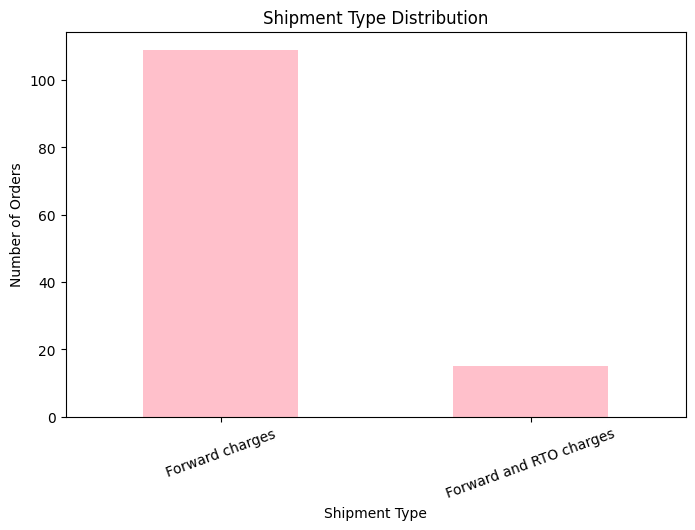

In [ ]:
shipment_counts = invoice[
    "Type of Shipment"
].value_counts()

plt.figure(figsize=(8,5))

shipment_counts.plot(
    kind="bar",color="pink"
)

plt.title("Shipment Type Distribution")
plt.xlabel("Shipment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)

plt.show()

Visualization 10: Correct vs Incorrect Charges

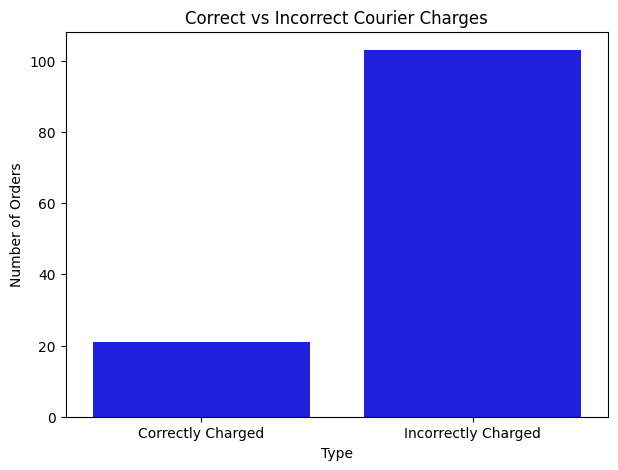

In [ ]:
correct_incorrect = pd.DataFrame({
    "Type": [
        "Correctly Charged",
        "Incorrectly Charged"
    ],
    "Orders": [
        correct_orders,
        overcharged_orders + undercharged_orders
    ]
})

plt.figure(figsize=(7,5))

sns.barplot(
    data=correct_incorrect,
    x="Type",
    y="Orders",color="blue"
)

plt.title("Correct vs Incorrect Courier Charges")
plt.ylabel("Number of Orders")

plt.show()

Create Final Excel File

In [ ]:
output_file = "Cointab_Data_Analyst_Challenge_Final.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    summary.to_excel(
        writer,
        sheet_name="Summary Table",
        index=False
    )

    order_level.to_excel(
        writer,
        sheet_name="Order Level Calculation",
        index=False
    )

    order_level_working.to_excel(
        writer,
        sheet_name="Working Data",
        index=False
    )

print("Excel file created successfully!")

Excel file created successfully!


Verify the Excel File

In [ ]:
check_summary = pd.read_excel(
    output_file,
    sheet_name="Summary Table"
)

check_order = pd.read_excel(
    output_file,
    sheet_name="Order Level Calculation"
)

print("Summary Table:")
display(check_summary)

print("\nOrder Level Calculation:")
display(check_order.head())

print(
    "\nNumber of order-level records:",
    len(check_order)
)

Summary Table:


,Metric,Value
0,Total Orders,124.0
1,Total Orders where X has been correctly charged,21.0
2,Total Orders where X has been overcharged,80.0
3,Total Overcharging Amount (Rs.),4483.2
4,Total Orders where X has been undercharged,23.0
5,Total Undercharging Amount (Rs.),575.1



Order Level Calculation:


,Order ID,AWB Number,Total weight as per X (KG),Weight slab as per X (KG),Total weight as per Courier Company (KG),Weight slab charged by Courier Company (KG),Delivery Zone as per X,Delivery Zone charged by Courier Company,Expected Charge as per X (Rs.),Charges Billed by Courier Company (Rs.),Difference Between Expected Charges and Billed Charges (Rs.)
0,2001806232,1091117222124,1.302,1.5,1.30,1.5,d,d,135.0,135.0,0.0
1,2001806273,1091117222194,0.615,1.0,1.00,1.0,d,d,90.2,90.2,0.0
2,2001806408,1091117222931,2.265,2.5,2.50,2.5,d,d,224.6,224.6,0.0
3,2001806458,1091117223244,0.700,1.0,1.00,1.0,b,b,61.3,61.3,0.0
4,2001807012,1091117229345,0.240,0.5,0.15,0.5,d,d,45.4,45.4,0.0



Number of order-level records: 124


Download Final Excel

In [ ]:
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>